In [44]:

from google.colab import files

uploaded = files.upload()


Saving spam_sms.csv to spam_sms (6).csv


In [45]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")


Libraries imported successfully!


In [46]:

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename, encoding="latin-1")

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())


Original shape: (5572, 2)
Columns: ['v1', 'v2']
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [47]:

# Identify message and label columns
text_col = next(
    (c for c in df.columns
     if c.lower() in ["v2", "message", "text", "sms", "content"]),
    None
)

label_col = next(
    (c for c in df.columns
     if c.lower() in ["v1", "label", "category", "target", "type"]),
    None
)

if text_col is None or label_col is None:
    raise ValueError("Check the column names printed above.")

df = df[[text_col, label_col]].copy()
df.columns = ["message", "label"]

# Handle missing values
df = df.dropna(subset=["message", "label"])

df["message"] = df["message"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.lower().str.strip()

# Keep spam and ham labels only
df = df[df["label"].isin(["spam", "ham"])]

# Remove empty messages and duplicates
df = df[df["message"] != ""]
df = df.drop_duplicates()

# Select approximately 2,000 messages
df = df.sample(n=min(2000, len(df)), random_state=42)
df = df.reset_index(drop=True)

# ham = 0, spam = 1
df["label"] = df["label"].map({"ham": 0, "spam": 1})

print("Cleaned dataset shape:", df.shape)
print(df["label"].value_counts())
print(df.head())


Cleaned dataset shape: (2000, 2)
label
0    1740
1     260
Name: count, dtype: int64
                                             message  label
0      &lt;#&gt;  am I think? Should say on syllabus      0
1     2mro i am not coming to gym machan. Goodnight.      0
2  Carlos'll be here in a minute if you still nee...      0
3    Id onluy matters when getting on from offcampus      0
4             Except theres a chick with huge boobs.      0


In [48]:

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["message"] = df["message"].apply(clean_text)

print(df[["message", "label"]].head())
print("Text preprocessing completed!")


                                             message  label
0            lt gt am i think should say on syllabus      0
1       2mro i am not coming to gym machan goodnight      0
2  carlos ll be here in a minute if you still nee...      0
3    id onluy matters when getting on from offcampus      0
4              except theres a chick with huge boobs      0
Text preprocessing completed!


In [49]:

# Change these settings if required
MAX_WORDS = 5000
MAX_LEN = 50

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(df["message"])

sequences = tokenizer.texts_to_sequences(df["message"])

X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y = df["label"].values

print("Numerical sequence example:")
print(X[0])

print("Input shape:", X.shape)
print("Label shape:", y.shape)


Numerical sequence example:
[  44   43   71    2  129  130  142   19 2164    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]
Input shape: (2000, 50)
Label shape: (2000,)


In [50]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1600
Testing samples: 400


In [51]:

# Model settings can be changed here
EMBEDDING_DIM = 32
LSTM_UNITS = 32
DROPOUT_RATE = 0.3

model = Sequential([
    Embedding(MAX_WORDS, EMBEDDING_DIM),
    LSTM(LSTM_UNITS),
    Dropout(DROPOUT_RATE),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [52]:

EPOCHS = 10
BATCH_SIZE = 32

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8570 - loss: 0.4540 - val_accuracy: 0.8562 - val_loss: 0.4177
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8734 - loss: 0.3888 - val_accuracy: 0.8562 - val_loss: 0.4155
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8734 - loss: 0.3876 - val_accuracy: 0.8562 - val_loss: 0.4135
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8734 - loss: 0.3760 - val_accuracy: 0.8562 - val_loss: 0.3063
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9492 - loss: 0.1530 - val_accuracy: 0.9594 - val_loss: 0.2053
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9789 - loss: 0.1265 - val_accuracy: 0.9563 - val_loss: 0.2026
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9828 - loss: 0.1000 - val_accuracy: 0.9594 - val_loss: 0.1844
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9867 - loss: 0.0808 - val_accuracy: 0.9594 - v

In [53]:

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
Accuracy : 0.96
Precision: 0.95
Recall   : 0.7308
F1-Score : 0.8261


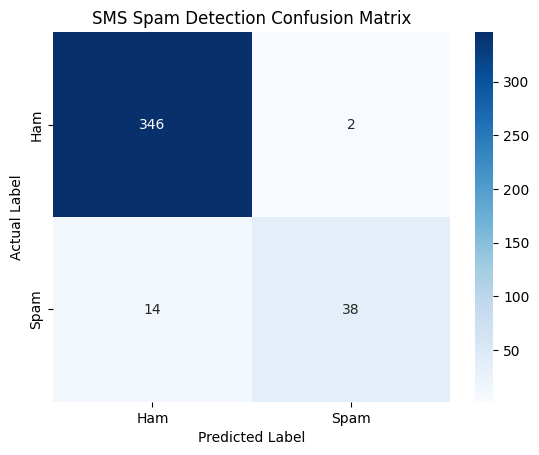

In [54]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection Confusion Matrix")
plt.show()


In [55]:

def predict_sms(message):
    cleaned = clean_text(message)

    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        seq,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = model.predict(padded, verbose=0)[0][0]

    if probability >= 0.5:
        result = "SPAM"
    else:
        result = "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print("Spam probability:", round(float(probability), 4))
    print("-" * 40)

predict_sms("Congratulations! You won a free prize. Claim now!")
predict_sms("Hi, I will meet you at college tomorrow.")
predict_sms("URGENT! Claim your cash reward now!")
predict_sms("Please call me when you reach home.")


Message: Congratulations! You won a free prize. Claim now!
Prediction: SPAM
Spam probability: 0.9119
----------------------------------------
Message: Hi, I will meet you at college tomorrow.
Prediction: HAM
Spam probability: 0.0173
----------------------------------------
Message: URGENT! Claim your cash reward now!
Prediction: SPAM
Spam probability: 0.9119
----------------------------------------
Message: Please call me when you reach home.
Prediction: HAM
Spam probability: 0.0173
----------------------------------------


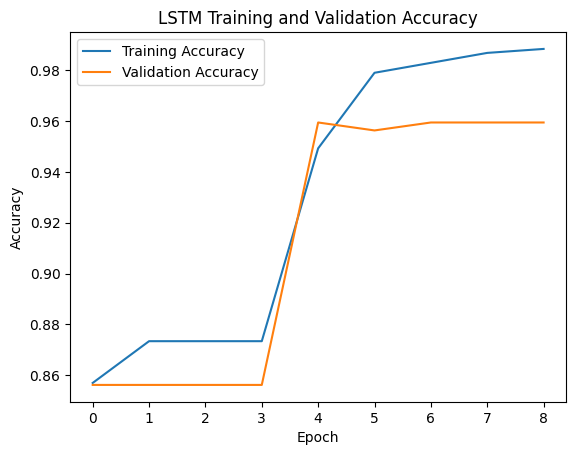

In [56]:

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.show()
